# The regression experiment

## is the price correlated to distance to nearest station

## for each meter away from subway station how does the price vary

we start by importing the usual suspects

In [30]:
# import data science libraries
import pandas as pd
import numpy as np

# import advanced plot drawing library
import seaborn as sns 

# import data science library with added geographic functions
import geopandas as gpd

# useful to calculate the Ordinary Least Square linear regression
import statsmodels 

# useful to get fast distance calculation, 
# see https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.BallTree.html
from sklearn.neighbors import BallTree 

# useful to access functions like median, mean or std 
from scipy import stats 

# useful to get map background but hard to install...
# If not available REMOVE this
import contextily as cx

sns.set_style("white")

## 1 – Real Estate dataset: Anjuke

This dataset has been created in UTSEUS in 2017. The souce page for it is (anjuke)[https://shanghai.anjuke.com/sale]

This dataset is given to you as a (pickle)[https://docs.python.org/3/library/pickle.html] which can be used directly as a variable.
The format is called pickle, it is like a zip but can only be read in python. 

In [31]:
# change path to your PATH. if the file can be seen on the left you can just put the file name directly
real_estate_file = 'utseus-anjuke-real-estate.pk'
anjuke = pd.read_pickle(real_estate_file)

the pickle is just a list of list. The first item is the columns name, the rest is the data
The dataframe need to have the data first, and the name of the columns separately. 
We use (list comprehension)[https://docs.python.org/3/tutorial/introduction.html#lists] to achieve this.

In [32]:
anjuke_df = pd.DataFrame(anjuke[1:], columns=anjuke[0])


Use .info or .describe functions to get a better idea of the dataset

In [33]:
# Convert relevant columns to numeric
columns_to_convert = ['longitude', 'latitude', 'bedroom', 'room', 'surface', 'onesquaremeter']
for col in columns_to_convert:
    anjuke_df[col] = pd.to_numeric(anjuke_df[col], errors='coerce')

# Convert categorical columns to category type
anjuke_df['address'] = anjuke_df['address'].astype('category')
anjuke_df['tags'] = anjuke_df['tags'].astype('category')
anjuke_df['district'] = anjuke_df['district'].astype('category')
anjuke_df['neighborhood'] = anjuke_df['neighborhood'].astype('category')
anjuke_df['done'] = anjuke_df['done'].astype('category')

# Check the updated DataFrame structure
anjuke_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467029 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              467029 non-null  object  
 1   address         467029 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         467029 non-null  int64   
 5   room            467029 non-null  int64   
 6   surface         467029 non-null  float64 
 7   price           467029 non-null  object  
 8   onesquaremeter  467029 non-null  float64 
 9   tags            467029 non-null  category
 10  district        467029 non-null  category
 11  neighborhood    467029 non-null  category
 12  done            467029 non-null  category
dtypes: category(5), float64(4), int64(2), object(2)
memory usage: 44.3+ MB


all of the field we see in the columns are object and have not been correctly imported as numbers. Consequently we cannot calculate with these columns as they are considered as words. We need numbers. To convert from words to numbers we use a special function from python. 

All numeric columns shall transformed into floats using pandas (to_numeric)[https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_numeric.html] function.

In [34]:
numeric_columns = ['longitude', 'latitude', 'bedroom', 'room', 'surface', 'price', 'onesquaremeter']

# put the function in the following line
anjuke_df[numeric_columns] = anjuke_df[numeric_columns].apply(pd.to_numeric, errors='coerce')


anjuke_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467029 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              467029 non-null  object  
 1   address         467029 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         467029 non-null  int64   
 5   room            467029 non-null  int64   
 6   surface         467029 non-null  float64 
 7   price           467029 non-null  float64 
 8   onesquaremeter  467029 non-null  float64 
 9   tags            467029 non-null  category
 10  district        467029 non-null  category
 11  neighborhood    467029 non-null  category
 12  done            467029 non-null  category
dtypes: category(5), float64(5), int64(2), object(1)
memory usage: 44.3+ MB


now we can have some numbers that could not be converted. the rows containing these undefined values need to be dropped. 

Do that using the function (dropna)[https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html]

In [35]:

anjuke_df = anjuke_df.dropna()

anjuke_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 463067 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              463067 non-null  object  
 1   address         463067 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         463067 non-null  int64   
 5   room            463067 non-null  int64   
 6   surface         463067 non-null  float64 
 7   price           463067 non-null  float64 
 8   onesquaremeter  463067 non-null  float64 
 9   tags            463067 non-null  category
 10  district        463067 non-null  category
 11  neighborhood    463067 non-null  category
 12  done            463067 non-null  category
dtypes: category(5), float64(5), int64(2), object(1)
memory usage: 47.6+ MB


check if the colums have been successfully changed.

You should observe that we 'lost' 3962 records that were incomplete with a non numeric data

use .info() again

In [36]:
anjuke_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 463067 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              463067 non-null  object  
 1   address         463067 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         463067 non-null  int64   
 5   room            463067 non-null  int64   
 6   surface         463067 non-null  float64 
 7   price           463067 non-null  float64 
 8   onesquaremeter  463067 non-null  float64 
 9   tags            463067 non-null  category
 10  district        463067 non-null  category
 11  neighborhood    463067 non-null  category
 12  done            463067 non-null  category
dtypes: category(5), float64(5), int64(2), object(1)
memory usage: 47.6+ MB


Time to tranform the dataset into a geodataframe now so we can perform geographic operations

Right now we just have GPS has numbers in columns. This is not ready to be used on a map. For that we need to convert it into a geographic object that can be a point, a line or a polygon. In our case it is a point 

In [37]:
anjuke_gdf = gpd.GeoDataFrame(
        anjuke_df, 
        geometry=gpd.points_from_xy(anjuke_df.longitude, anjuke_df.latitude), crs=4326)

anjuke_gdf.info()  # Check structure and data types


<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 463067 entries, 0 to 467028
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              463067 non-null  object  
 1   address         463067 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         463067 non-null  int64   
 5   room            463067 non-null  int64   
 6   surface         463067 non-null  float64 
 7   price           463067 non-null  float64 
 8   onesquaremeter  463067 non-null  float64 
 9   tags            463067 non-null  category
 10  district        463067 non-null  category
 11  neighborhood    463067 non-null  category
 12  done            463067 non-null  category
 13  geometry        463067 non-null  geometry
dtypes: category(5), float64(5), geometry(1), int64(2), object(1)
memory usage: 51.1+ MB


plot the data on a map using the plot function with the following properties
plot(markersize=0.5, color='black', figsize=(10,10))

longitude    float64
latitude     float64
dtype: object


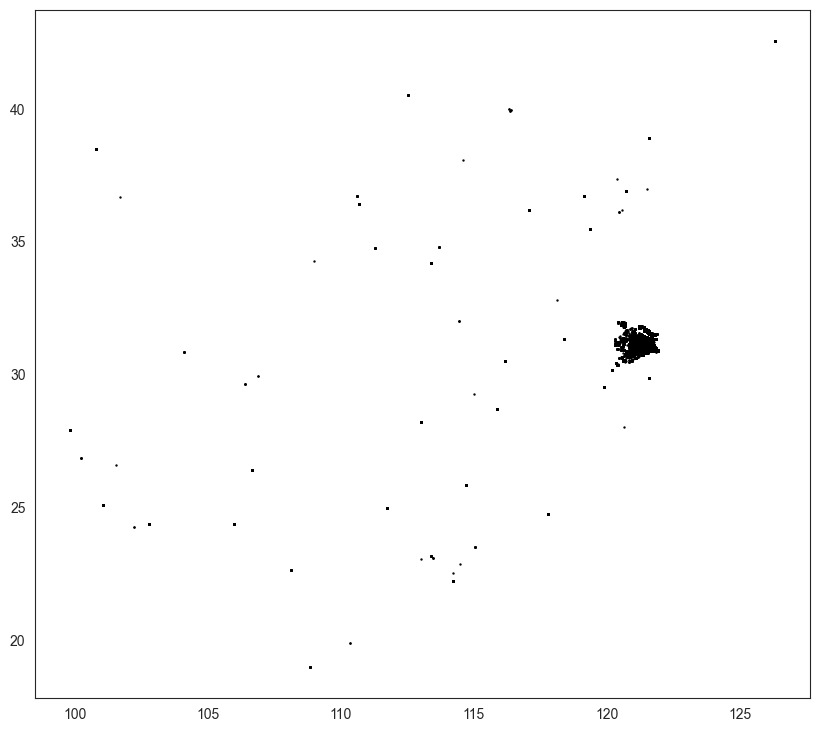

In [38]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Vérifie que les colonnes latitude et longitude existent et sont bien numériques
print(anjuke_df[['longitude', 'latitude']].dtypes)

# Transformer en GeoDataFrame
anjuke_gdf = gpd.GeoDataFrame(
    anjuke_df, 
    geometry=gpd.points_from_xy(anjuke_df.longitude, anjuke_df.latitude)
)

# Tracer la carte
anjuke_gdf.plot(
    markersize=0.5, 
    color='black', 
    figsize=(10,10)
)
plt.show()



We observe that data are not only in Shanghai. 

Write HERE why you think it is like this ? 

The data might include locations outside Shanghai due to incorrect GPS entries, listings from other cities, or errors during data collection.


To have an idea of the spread of data, we can print or we can check the boundaries using the property (total_bounds)[https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.total_bounds.html]

In [39]:
import geopandas as gpd

# Convert the DataFrame to a GeoDataFrame if it's not already one
anjuke_gdf = gpd.GeoDataFrame(anjuke_df, geometry=gpd.points_from_xy(anjuke_df.longitude, anjuke_df.latitude))

# Get the total bounds
bounds = anjuke_gdf.total_bounds

# Print the result
print("Longitude min:", bounds[0])
print("Latitude min:", bounds[1])
print("Longitude max:", bounds[2])
print("Latitude max:", bounds[3])


Longitude min: 99.8241059144697
Latitude min: 18.9936962794355
Longitude max: 126.330392528475
Latitude max: 42.5494092607921


In both cases, it seems there are data outside Shanghai.

To limit it we have two options:
- one is to use _cx_ to specify a bounding box
- another one is to provide a shape for the area and filter points within

### Lets start with bounding box

to find the bounding box you can use GIS or search for it. we can use [bboxfinder.com](http://bboxfinder.com/)  for example

In [40]:
print(f'before {len(anjuke_gdf)}')
west =121.10157
east = 121.804611
north = 31.514999
south = 30.975
xmin, ymin, xmax, ymax = (west,south,east,north)
anjuke_filterbb_gdf = anjuke_gdf.cx[xmin:xmax, ymin:ymax]
print(f'after {len(anjuke_filterbb_gdf)}')



before 463067
after 392383


we check if the latitude or longitude we have is in GCJ format of GPS format by looking at the huangpu river

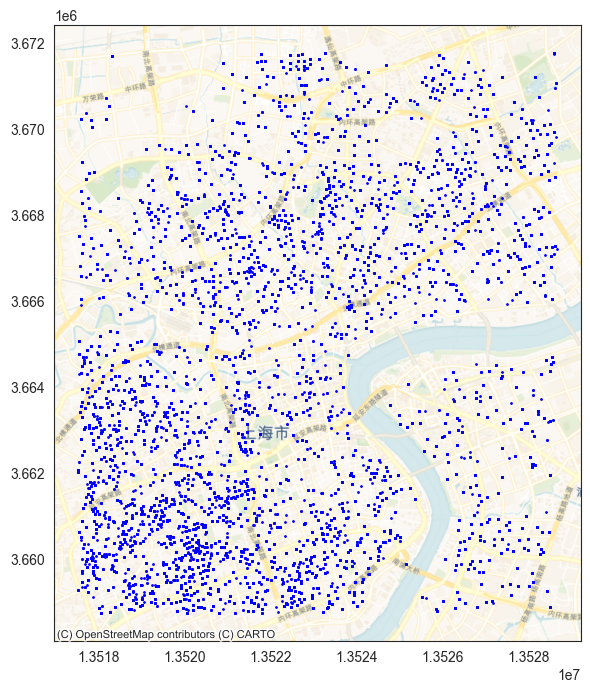

In [41]:
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt

# Assuming you've already filtered your dataset as anjuke_filterbb_gdf

# Set CRS to EPSG:4326 (WGS84) if it's not already set
anjuke_filterbb_gdf = anjuke_filterbb_gdf.set_crs("EPSG:4326", allow_override=True)

# Create a plot with the data in Web Mercator (EPSG:3857)
ax = anjuke_filterbb_gdf.cx[121.43:121.53, 31.20:31.30].to_crs(3857).plot(markersize=1, color='b', figsize=(8,8))

# Add a basemap to the plot using contextily's CartoDB Voyager tiles
cx.add_basemap(ax, source=cx.providers.CartoDB.Voyager)

# Show the plot
plt.show()


## 2 – POI dataset: Gaode

This dataset has been bought from Gaode for SHU Cendus institute in 2020. We choose the POI from 2017 to be consistant with the anjuke dataset also from 2017 

In [42]:
poi_df = pd.read_csv('shanghaiPOI2017.csv',delimiter=';', decimal=',', low_memory=False)

In [43]:
poi_df.columns

Index(['Unnamed: 0', 'ID', 'POIID', 'GCJX', 'GCJY', 'NAME', 'ADD', 'TEL',
       'TYPE', 'AREAID', 'IDKEY', 'GPSX', 'GPSY', 'TYPE1', 'TYPE2', 'TYPE3',
       'TYPE4', 'TYPE5', 'TYPE3.1', 'TYPE3.2', 'TYPE3.3', 'TYPE1.N', 'TYPE2.N',
       'TYPE3.N', 'TYPE3.1.N', 'TYPECODE', 'GBCODE'],
      dtype='object')

find the GBCode corresponding to subway stations. one column seems to have a text, we can search in the text.

In [44]:
# Search for subway (地铁) in the 'TYPECODE' column and select 'TYPECODE' and 'GBCODE'
subway_gbcode = poi_df[poi_df.TYPECODE.str.contains('地铁')].loc[:, ['TYPECODE', 'GBCODE']]

# Display the result
print(subway_gbcode)


             TYPECODE    GBCODE
69644  交通设施服务;地铁站;出入口  200402.0
69645  交通设施服务;地铁站;出入口  200402.0
69646  交通设施服务;地铁站;出入口  200402.0
69647  交通设施服务;地铁站;出入口  200402.0
69648  交通设施服务;地铁站;出入口  200402.0
...               ...       ...
71345  交通设施服务;地铁站;地铁站  200401.0
71346  交通设施服务;地铁站;地铁站  200401.0
71347  交通设施服务;地铁站;地铁站  200401.0
71348  交通设施服务;地铁站;地铁站  200401.0
71349  交通设施服务;地铁站;地铁站  200401.0

[1706 rows x 2 columns]


it looks like the subway stations have a GBCode of XXXX.

The complete description of China BGCode used to categorize POI information can be found [GB/T 35648-2017 ](https://openstd.samr.gov.cn/bzgk/gb/newGbInfo?hcno=3330BB5A1FF81A61F8A7432B0BB4AE01)

In [45]:
GBCODE = 200401  # or 200402
poi_subway_df = poi_df[poi_df.GBCODE == GBCODE]


In [46]:
poi_subway_df

,Unnamed: 0,ID,POIID,GCJX,GCJY,NAME,ADD,TEL,TYPE,AREAID,...,TYPE5,TYPE3.1,TYPE3.2,TYPE3.3,TYPE1.N,TYPE2.N,TYPE3.N,TYPE3.1.N,TYPECODE,GBCODE
70929,70930,45,BV10470886,121.407219,31.250767,真如(地铁站),11号线,NaN,交通设施服务;地铁站;地铁站,310107,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
70930,70931,45,BV10470887,121.389969,31.269020,李子园(地铁站),11号线,NaN,交通设施服务;地铁站;地铁站,310107,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
70931,70932,45,BV10470888,121.376035,31.271650,祁连山路(地铁站),11号线,NaN,交通设施服务;地铁站;地铁站,310107,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
70932,70933,45,BV10470889,121.364678,31.276646,武威路(地铁站),11号线,NaN,交通设施服务;地铁站;地铁站,310107,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
70933,70934,45,BV10470891,121.411402,31.241850,枫桥路(地铁站),11号线,NaN,交通设施服务;地铁站;地铁站,310107,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71345,71346,45,BV10040000,121.416582,31.026483,剑川路(地铁站),5号线,NaN,交通设施服务;地铁站;地铁站,310112,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
71346,71347,45,BV10040001,121.410186,31.011282,金平路(地铁站),5号线,NaN,交通设施服务;地铁站;地铁站,310112,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
71347,71348,45,BV10040002,121.395255,31.007467,华宁路(地铁站),5号线,NaN,交通设施服务;地铁站;地铁站,310112,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0
71348,71349,45,BV10040003,121.380775,31.003597,文井路(地铁站),5号线,NaN,交通设施服务;地铁站;地铁站,310112,...,NaN,地铁站,NaN,NaN,72388,1706,421,421,交通设施服务;地铁站;地铁站,200401.0


we proceed similarly with this dataframe and convert it to a geodataframe. Use the same technic as before

In [47]:
poi_subway_gdf = gpd.GeoDataFrame(
    poi_subway_df,
    geometry=gpd.points_from_xy(poi_subway_df.GPSX, poi_subway_df.GPSY),
    crs=4326
)


<Axes: >

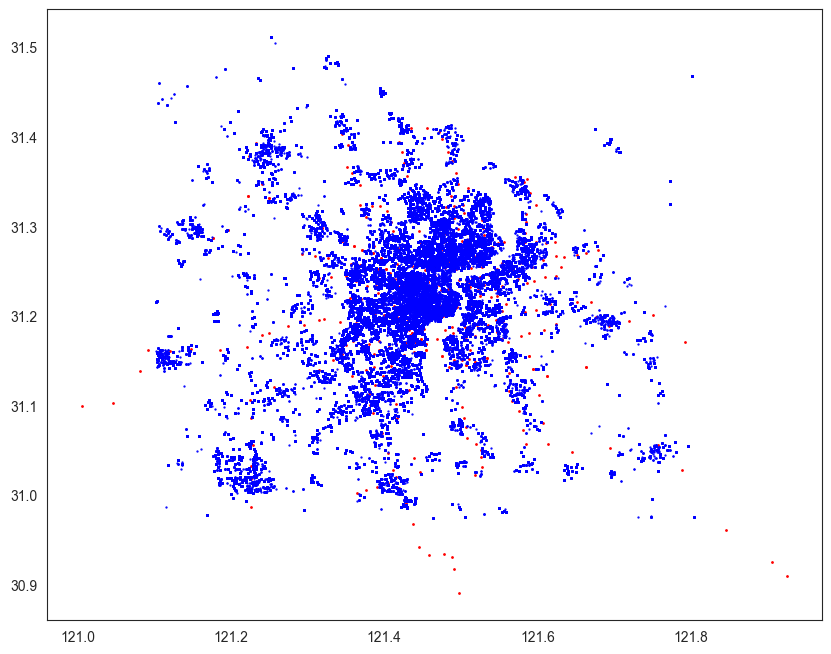

In [48]:
ax = poi_subway_gdf.plot(markersize=1, color='r', figsize=(10,10))
anjuke_filterbb_gdf.plot(ax=ax, markersize=0.4, color='b')


## 3 – Distance to nearest subway station

We calculate the distance from each apartment to the closest subway station using BallTree.


In [50]:
from sklearn.neighbors import BallTree
import numpy as np

# Convert apartment and subway coordinates to radians
apartments_rad = np.deg2rad(anjuke_filterbb_gdf[['latitude', 'longitude']].to_numpy())
subways_rad = np.deg2rad(poi_subway_gdf[['GPSY', 'GPSX']].to_numpy())

# Use BallTree to find nearest subway station for each apartment
tree = BallTree(subways_rad, metric='haversine')
distances, _ = tree.query(apartments_rad, k=1)

# Convert distances from radians to meters and add to the dataframe
anjuke_filterbb_gdf['distance_to_subway'] = distances.flatten() * 6371000


## 4 – Filter dataset for analysis

To make the analysis more reliable, we filter out apartments that are too far from subway stations (> 5 km) and those with extremely high price per square meter (> 100,000 RMB).


In [51]:
# Filter apartments within 5km of a subway station and reasonable price range
anjuke_filtered = anjuke_filterbb_gdf[
    (anjuke_filterbb_gdf['distance_to_subway'] <= 5000) &
    (anjuke_filterbb_gdf['onesquaremeter'] <= 100000)
]

# Check the number of remaining rows
print(f"Remaining apartments: {len(anjuke_filtered)}")


Remaining apartments: 342223


## 5 – Visualize the relationship between price and distance

We now plot the price per square meter against the distance to the nearest subway station to observe any trend.


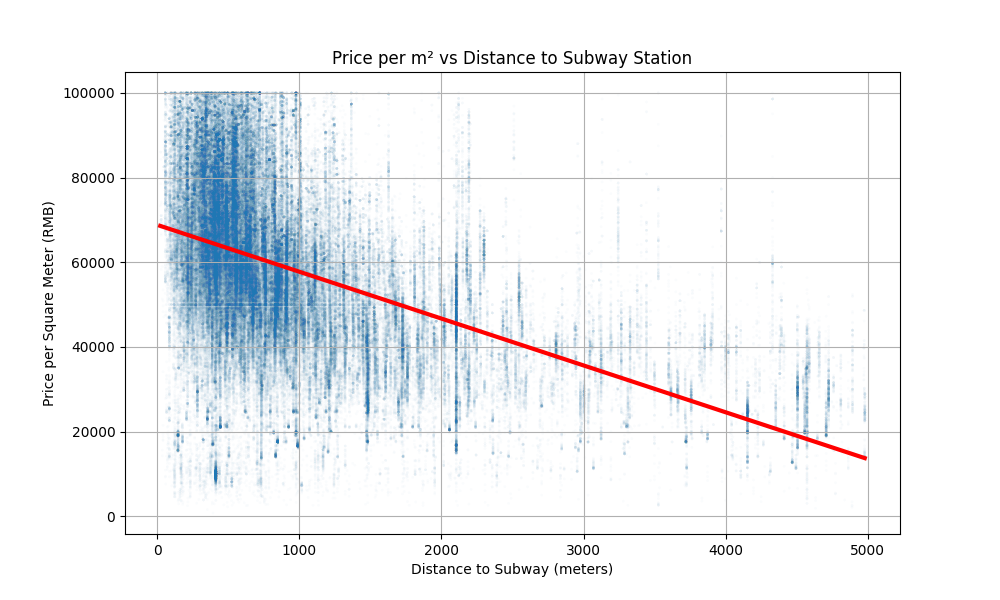

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot scatter + regression line
plt.figure(figsize=(10, 6))
sns.regplot(
    data=anjuke_filtered,
    x='distance_to_subway',
    y='onesquaremeter',
    ci=None,
    scatter_kws={'alpha': 0.02, 's': 4, 'edgecolor': 'none'},
    line_kws={'color': 'red', 'linewidth': 3}
)
plt.title('Price per m² vs Distance to Subway Station')
plt.xlabel('Distance to Subway (meters)')
plt.ylabel('Price per Square Meter (RMB)')
plt.grid(True)
plt.show()


## 6 – Linear regression

We now run a linear regression model to quantify how the distance to the subway affects the price per square meter.


In [53]:
import statsmodels.formula.api as smf

# Fit the linear model
model = smf.ols(formula='onesquaremeter ~ distance_to_subway', data=anjuke_filtered).fit()

# Show the results
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:         onesquaremeter   R-squared:                       0.217
Model:                            OLS   Adj. R-squared:                  0.217
Method:                 Least Squares   F-statistic:                 9.490e+04
Date:                Fri, 23 May 2025   Prob (F-statistic):               0.00
Time:                        15:47:13   Log-Likelihood:            -3.8326e+06
No. Observations:              342223   AIC:                         7.665e+06
Df Residuals:                  342221   BIC:                         7.665e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           6.883e+04     45

## Conclusion

**Is the price correlated to distance to nearest station?**

The analysis shows a clear and statistically significant relationship between the price per square meter and the distance to the nearest subway station in Shanghai.

For every meter further away from a station, the price decreases by approximately **11 RMB/m²**.  
The model explains around **21.7% of the price variation**, which is meaningful, but not enough to fully predict apartment prices on its own.  
This confirms that **proximity to public transport is a key factor** influencing real estate value, even if other factors also play a role.
